# 02 · A model at a fixed false-positive rate

In account opening, every flagged application is either rejected or sent for manual
checks, and both cost a legitimate customer time or the account altogether. Banks
therefore fix the **false-positive rate** (FPR), the share of *legitimate* applicants
flagged, and ask how much fraud is caught there. Following the BAF paper, we use
**5 % FPR** and report **recall at 5 % FPR**.

This notebook:
1. compares a logistic-regression baseline with LightGBM at that operating point;
2. reports the final model on the test months (6–7);
3. shows that **a threshold chosen in one month doesn't deliver 5 % FPR in the next**,
   and compares ways to keep the operating point under control;
4. explains what drives the model, setting up the fairness audit in notebook 03.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from fraudkit import baf
from fraudkit.fairness import rates, recall_at_fpr, threshold_at_fpr
from fraudkit.metrics import bootstrap_ci, paired_bootstrap_diff
from fraudkit.plotting import INK_2, MUTED, SEQUENTIAL, SERIES, finish, label_bars, set_style

set_style()
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.4f}".format)
FPR = 0.05

df = baf.load()
FEATURES = baf.features(df)
y = df.fraud_bool.values
month = df.month.values
TRAIN, VAL, TEST = month <= 4, month == 5, month >= 6
print(f"{len(FEATURES)} features · train months 0–4: {TRAIN.sum():,} · validation month 5: {VAL.sum():,} "
      f"· test months 6–7: {TEST.sum():,}")

/home/newf/projects/fraud-detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


29 features · train months 0–4: 675,666 · validation month 5: 119,323 · test months 6–7: 205,011


## 1. The operating point

A **ROC curve** plots recall (true-positive rate) against FPR as the threshold moves.
ROC-AUC averages over *all* thresholds, but the business only operates at one, so we read
the curve at FPR = 5 %. Unlike PR-AUC, this metric doesn't depend on the fraud rate. That
helps when the rate drifts between months, as it does here.

Validation design: train on months 0–4, choose models and settings on month 5, and test
once on months 6–7 after refitting on months 0–5.

## 2. Baseline: logistic regression

Linear models need explicit preprocessing: missing values imputed **plus a
missing-indicator column** (notebook 01 showed that missingness carries signal), numeric
features scaled, categories one-hot encoded. `class_weight="balanced"` compensates for the
1 % fraud rate (project 1, notebook 02).

In [2]:
cat_cols = [c for c in FEATURES if df[c].dtype == "category"]
num_cols = [c for c in FEATURES if c not in cat_cols]
pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
logreg = make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight="balanced"))
logreg.fit(df.loc[TRAIN, FEATURES], y[TRAIN])
val_scores = {"Logistic regression": logreg.predict_proba(df.loc[VAL, FEATURES])[:, 1]}

## 3. LightGBM

Trained on months 0–4 with early stopping on month 5's ROC-AUC (patience 200 rounds).
Categories are passed as integer codes with LightGBM's native categorical handling.

In [3]:
lgbm = baf.fit(df, TRAIN, FEATURES, 5000, valid_rows=VAL, early_stopping=200)
val_scores["LightGBM"] = baf.predict(lgbm, df, VAL, FEATURES)
print(f"LightGBM: best round {lgbm.best_iteration}")

rows = {}
for name, s in val_scores.items():
    r, lo, hi = bootstrap_ci(lambda yy, ss: recall_at_fpr(yy, ss, FPR), y[VAL], s, n_boot=300)
    rows[name] = {"recall @ 5 % FPR": r, "95 % CI": f"{lo:.3f}–{hi:.3f}", "ROC-AUC": roc_auc_score(y[VAL], s)}
gain = paired_bootstrap_diff(lambda yy, ss: recall_at_fpr(yy, ss, FPR), y[VAL],
                             val_scores["Logistic regression"], val_scores["LightGBM"], n_boot=300)
print(f"LightGBM − logistic regression: {gain[0]:+.3f} recall (95 % CI {gain[1]:+.3f} to {gain[2]:+.3f})")
pd.DataFrame(rows).T

LightGBM: best round 307


LightGBM − logistic regression: +0.025 recall (95 % CI +0.008 to +0.043)


,recall @ 5 % FPR,95 % CI,ROC-AUC
Logistic regression,0.5103,0.482–0.536,0.8829
LightGBM,0.5351,0.511–0.562,0.8971


**Reading it.** LightGBM catches **2.5 more frauds per 100** than logistic regression at
the same 5 % FPR (paired interval +0.8 to +4.3 points), and has the higher ROC-AUC.
The linear baseline is respectable because the signal here is many weak, mostly monotone
effects (notebook 01). LightGBM adds the interactions and goes forward.

## 4. Final model on the test months

Refit on months 0–5 with the number of rounds found above, scaled for the extra month of
data, then score months 6–7 once.

test recall @ 5 % FPR: 0.545 (95 % CI 0.527–0.564) · ROC-AUC 0.895


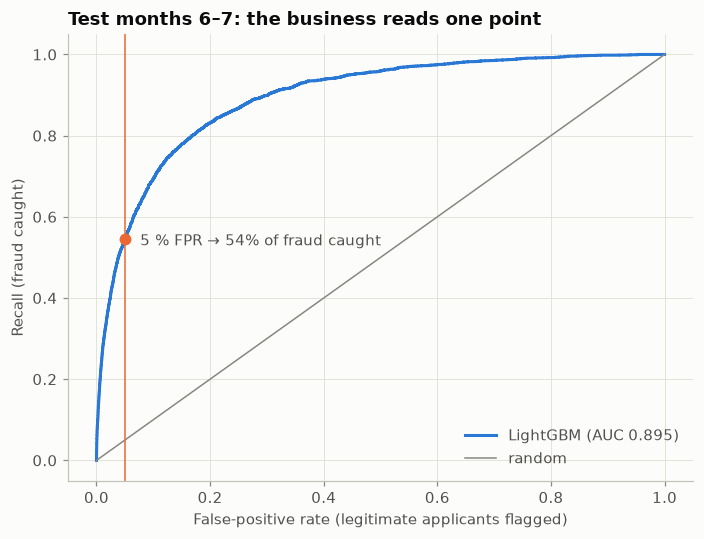

In [4]:
TRAIN_FULL = month <= 5
rounds = int(lgbm.best_iteration * TRAIN_FULL.sum() / TRAIN.sum())
final = baf.fit(df, TRAIN_FULL, FEATURES, rounds)
test_s = baf.predict(final, df, TEST, FEATURES)
y_te = y[TEST]

r, lo, hi = bootstrap_ci(lambda yy, ss: recall_at_fpr(yy, ss, FPR), y_te, test_s, n_boot=500)
auc = roc_auc_score(y_te, test_s)
print(f"test recall @ 5 % FPR: {r:.3f} (95 % CI {lo:.3f}–{hi:.3f}) · ROC-AUC {auc:.3f}")

fpr_c, tpr_c, _ = roc_curve(y_te, test_s)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(fpr_c, tpr_c, color=SERIES[0], lw=2, label=f"LightGBM (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, label="random")
ax.axvline(FPR, color=SERIES[1], lw=1)
ax.scatter([FPR], [r], color=SERIES[1], s=60, zorder=3)
ax.annotate(f"5 % FPR → {r:.0%} of fraud caught", (FPR, r), xytext=(10, -4), textcoords="offset points",
            color=INK_2)
ax.set_xlabel("False-positive rate (legitimate applicants flagged)")
ax.set_ylabel("Recall (fraud caught)")
ax.set_title("Test months 6–7: the business reads one point")
ax.legend(loc="lower right")
finish(fig)

For context, the BAF paper reports recall at 5 % FPR of roughly 0.5 for well-tuned
LightGBM models on the Base dataset, so this model is in the expected range.

## 5. The threshold doesn't travel: operating-point drift

In production the threshold has to be set **before** the month starts, from past data.
Notebook 01 showed the fraud rate rising and the velocity features drifting. Does a
threshold that gave 5 % FPR in month 5 still give 5 % in months 6 and 7?

Here we use the model trained on months 0–4, so month 5 is genuinely out-of-sample for
setting the threshold, and compare three policies per test month:

| Policy | How it is set | Needs labels from the new month? |
|---|---|---|
| **Fixed threshold** | the score threshold that gave 5 % FPR on month 5 | no |
| **Fixed flag rate** | flag the same *share* of applications as in month 5 (a quantile of the new month's scores) | no |
| **Oracle** | the threshold that gives exactly 5 % FPR in the month itself | yes (unavailable in practice, a reference) |

In [5]:
s_val = val_scores["LightGBM"]
t_fixed = threshold_at_fpr(y[VAL], s_val, FPR)
flag_rate_val = (s_val >= t_fixed).mean()
rows = []
for m in (6, 7):
    rm = month == m
    s_m, y_m = baf.predict(lgbm, df, rm, FEATURES), y[rm]
    policies = {
        "Fixed threshold": t_fixed,
        "Fixed flag rate": np.quantile(s_m, 1 - flag_rate_val),
        "Oracle": threshold_at_fpr(y_m, s_m, FPR),
    }
    for name, t in policies.items():
        r_ = rates(y_m, s_m >= t)
        rows.append({"month": m, "policy": name, "FPR": r_["FPR"], "recall": r_["TPR"], "flag rate": r_["flag rate"]})
drift = pd.DataFrame(rows)
drift.pivot(index="policy", columns="month", values=["FPR", "recall", "flag rate"])

FPR        recall        flag rate       
month                6      7      6      7         6      7
policy                                                      
Fixed flag rate 0.0493 0.0481 0.5317 0.5693    0.0557 0.0557
Fixed threshold 0.0653 0.0533 0.5814 0.5868    0.0722 0.0612
Oracle          0.0500 0.0500 0.5324 0.5784    0.0565 0.0578

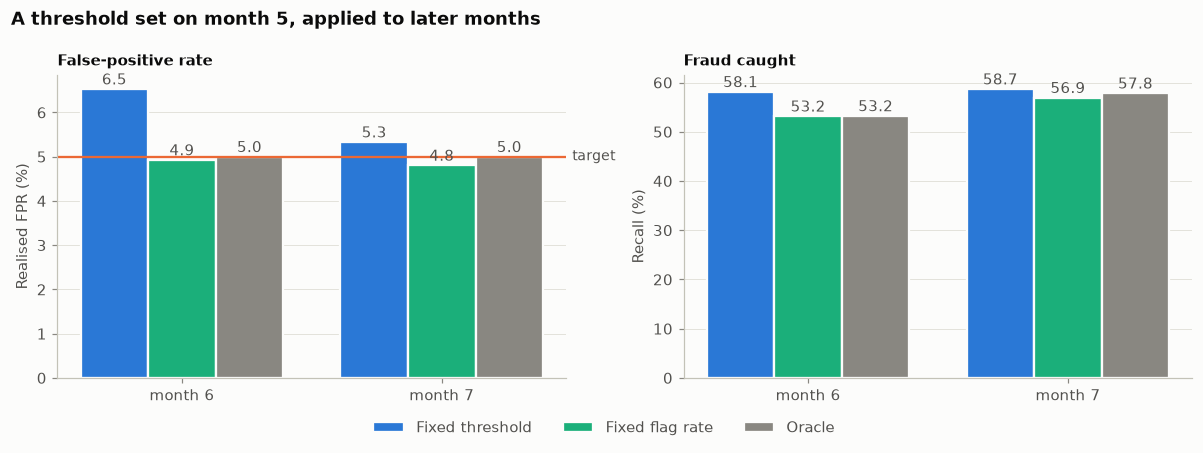

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
names = ["Fixed threshold", "Fixed flag rate", "Oracle"]
for ax, metric in zip(axes, ["FPR", "recall"]):
    x = np.arange(2)
    w = 0.26
    for i, (name, color) in enumerate(zip(names, [SERIES[0], SERIES[2], MUTED])):
        vals = drift[drift.policy == name].sort_values("month")[metric].values * 100
        bars = ax.bar(x + (i - 1) * w, vals, width=w, color=color, label=name, edgecolor="#fcfcfb", linewidth=1.5)
        label_bars(ax, bars, fmt="{:.1f}")
    ax.set_xticks(x, ["month 6", "month 7"])
    ax.grid(axis="x", visible=False)
axes[0].axhline(FPR * 100, color=SERIES[1], lw=1.5)
axes[0].annotate("target", xy=(1, FPR * 100), xycoords=("axes fraction", "data"), xytext=(4, 0),
                 textcoords="offset points", va="center", color=INK_2, fontsize=9)
axes[0].set_ylabel("Realised FPR (%)"); axes[0].set_title("False-positive rate", fontsize=10)
axes[1].set_ylabel("Recall (%)"); axes[1].set_title("Fraud caught", fontsize=10)
fig.legend(*axes[1].get_legend_handles_labels(), loc="lower center", ncols=3, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("A threshold set on month 5, applied to later months", x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.**
* **The fixed threshold over-flags legitimate applicants.** In month 6 the realised FPR is
  **6.5 %** instead of 5 %, so 30 % more good customers are rejected or delayed than the
  business agreed to. Its higher recall is bought with exactly that extra friction. In
  month 7 the excess is smaller (5.3 %).
* **The fixed flag rate holds the target** (4.9 % and 4.8 %) and catches nearly as much
  fraud as the oracle. Fraud is only ~1.3 % of applications, so the share flagged is
  almost entirely legitimate applicants. Holding the *flag rate* fixed therefore nearly
  holds the FPR fixed. It needs **no new labels**: a quantile of this month's scores
  (computed daily or weekly in practice) is enough.
* **Why the threshold moved:** the whole score distribution shifted between months
  (drifting inputs such as the velocity features, notebook 01). A raw score threshold is
  tied to the old distribution; a quantile adapts to the new one.

**Recommendation:** operate on a flag-rate (quantile) threshold, refreshed frequently, and
check the realised FPR once each month's labels mature.

### Does removing the drifting features help?

The velocity features drift most (notebook 01). One option is to drop them and accept a
possible loss of signal in exchange for stability. Same model, same protocol, without
`velocity_6h`, `velocity_24h` and `velocity_4w`:

In [7]:
NO_VEL = [f for f in FEATURES if not f.startswith("velocity_")]
lgbm_nv = baf.fit(df, TRAIN, NO_VEL, 5000, valid_rows=VAL, early_stopping=200)
s_val_nv = baf.predict(lgbm_nv, df, VAL, NO_VEL)
t_nv = threshold_at_fpr(y[VAL], s_val_nv, FPR)
rows = []
for name, model, feats, t in [("all features", lgbm, FEATURES, t_fixed), ("without velocity", lgbm_nv, NO_VEL, t_nv)]:
    for m in (6, 7):
        rm = month == m
        s_m = baf.predict(model, df, rm, feats)
        r_ = rates(y[rm], s_m >= t)
        rows.append({"features": name, "month": m, "realised FPR": r_["FPR"], "recall (fixed threshold)": r_["TPR"],
                     "recall @ 5 % FPR (oracle)": recall_at_fpr(y[rm], s_m, FPR)})
pd.DataFrame(rows).set_index(["features", "month"])

realised FPR  recall (fixed threshold)  \
features         month                                           
all features     6            0.0653                    0.5814   
                 7            0.0533                    0.5868   
without velocity 6            0.0598                    0.5614   
                 7            0.0452                    0.5644   

                        recall @ 5 % FPR (oracle)  
features         month                             
all features     6                         0.5324  
                 7                         0.5784  
without velocity 6                         0.5276  
                 7                         0.5777

**Reading it.** Without the velocity features, recall at the oracle 5 % FPR is unchanged
(0.528 vs 0.532 in month 6, 0.578 vs 0.578 in month 7), so they carry little signal the
other features don't. But the threshold drifts just as much, only in a different
direction (6.0 % then 4.5 %). Dropping the most-drifting features doesn't solve
operating-point drift. The quantile policy above does, so we keep all features.

## 6. What drives the model?

SHAP values (as in projects 1–2) for 5,000 test applications, all frauds among them
included.

customer_age ranks 17 of 29 (mean |SHAP| 0.102)


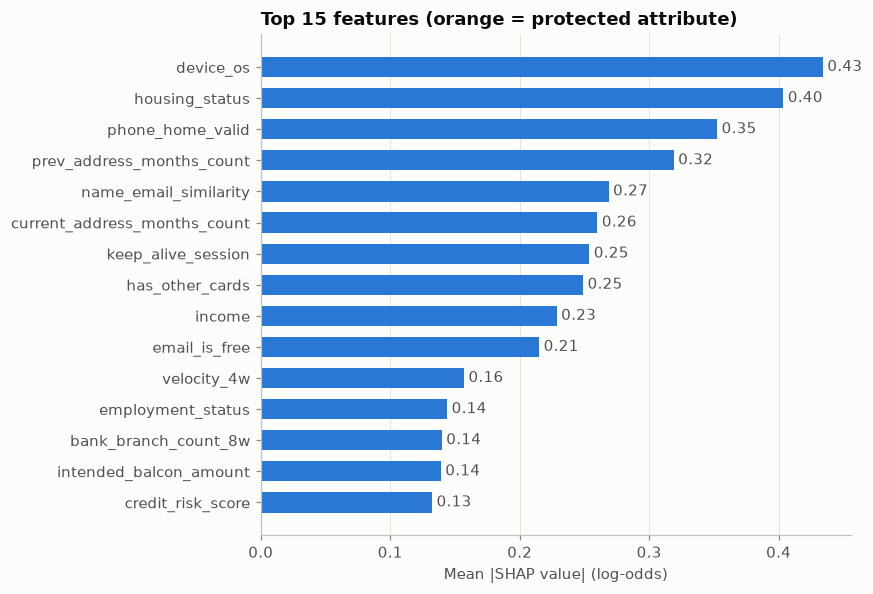

In [8]:
rng = np.random.default_rng(0)
te_idx = np.where(TEST)[0]
pick = np.r_[rng.choice(te_idx[y[te_idx] == 1], 1000, replace=False),
             rng.choice(te_idx[y[te_idx] == 0], 4000, replace=False)]
mask = np.zeros(len(df), bool); mask[pick] = True
X_shap, _ = baf.matrix(df, FEATURES, mask)
sv = shap.TreeExplainer(final)(pd.DataFrame(X_shap, columns=FEATURES))
if sv.values.ndim == 3:
    sv = sv[..., 1]

importance = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print(f"customer_age ranks {importance.index.get_loc(baf.PROTECTED) + 1} of {len(FEATURES)} "
      f"(mean |SHAP| {importance[baf.PROTECTED]:.3f})")
mean_abs = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(mean_abs.index, mean_abs.values, height=0.65,
               color=[SERIES[1] if f == baf.PROTECTED else SERIES[0] for f in mean_abs.index])
label_bars(ax, bars, fmt="{:.2f}", horizontal=True)
ax.set_xlabel("Mean |SHAP value| (log-odds)")
ax.set_title("Top 15 features (orange = protected attribute)")
ax.grid(axis="y", visible=False)
finish(fig)

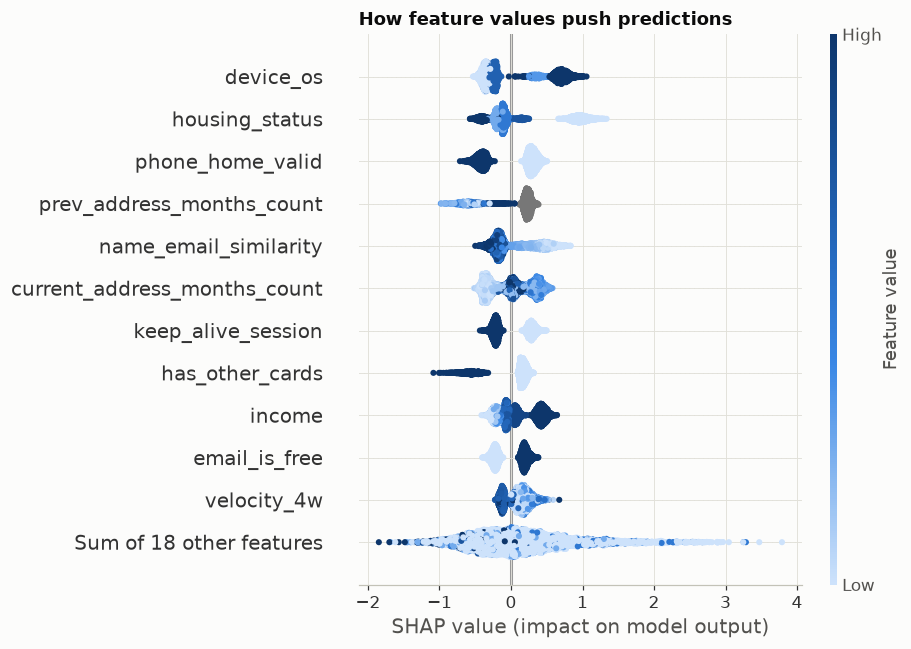

In [9]:
plt.figure()
shap.plots.beeswarm(sv, max_display=12, show=False, color=SEQUENTIAL)
plt.gca().set_title("How feature values push predictions", loc="left", fontweight="bold")
plt.gcf().set_size_inches(8.5, 6)
finish()

**Reading it.** The model leans on how the application was made and how verifiable the
applicant is: **Windows devices**, housing status `BA`, **no valid home phone**, a missing
previous address (grey = missing, pushes towards fraud), **low name–e-mail similarity**,
a session that wasn't kept alive, **high income** and **free e-mail** all push towards
fraud. (For categorical features such as `device_os` the colour shows the category code,
not a magnitude.)

**`customer_age` ranks only 17th of 29.** The age column itself contributes little, yet
notebook 01 showed fraud prevalence rising steeply with age. Notebook 03 asks whether
older *legitimate* applicants nevertheless get flagged more often, and if so, through
which features.

## 7. Conclusions

| Question | Answer |
|---|---|
| Best model at 5 % FPR? | LightGBM: recall **0.545** on test months 6–7 (95 % CI 0.527–0.564), ROC-AUC 0.895, in line with the BAF paper. Logistic regression is 2.5 points behind. |
| Does a threshold set on month 5 hold? | No: realised FPR 6.5 % in month 6, 30 % above target. |
| Fix? | Threshold on a **fixed flag rate** (score quantile of the current period): 4.8–4.9 % FPR with nearly oracle recall, no labels needed. |
| Drop the drifting velocity features? | They add little signal, but dropping them doesn't stabilise the threshold. |
| Role of age? | Small directly (rank 17 of 29). Notebook 03 checks its effect on errors. |

**Next:** [03 · Fairness audit](03_fairness.ipynb)